# Task 5: improving the FER baseline
Start from the completed Task 1 HOG + RBF SVM model. Compare regularization,
class weighting, feature selection and additional facial geometry using the
official validation split. Freeze the validation winner before final test evaluation.


In [1]:
from pathlib import Path
import sys, json, time, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
# Notebook paths are relative to the project root.
ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.emotion_features import LABELS, LANDMARK_CONFIG, load_predictor
from src.teammate_features import HOG_CONFIG,extract_model_features,IMPLEMENTATION,FEATURE_SOURCES
SEED = 42
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['numpy','pandas','scikit-learn','scipy','matplotlib','joblib','scikit-image','opencv-python','dlib']}
print('Python:', platform.python_version(), VERSIONS)

OUT = ROOT / 'results/teammate_task5'; OUT.mkdir(parents=True,exist_ok=True)

Python: 3.13.7 {'numpy': '2.5.4', 'pandas': '2.3.0', 'scikit-learn': '1.7.2', 'scipy': '1.18.1', 'matplotlib': '3.10.3', 'joblib': '1.6.0', 'scikit-image': '0.26.0', 'opencv-python': '4.11.0.86', 'dlib': '20.0.1'}


In [2]:
def load_split(name):
    """Read one of the prepared official FER partitions."""
    df = pd.read_csv(ROOT / 'data' / f'fer2013_{name}.csv')
    # Each CSV row stores a 48 x 48 grayscale face as 2,304 space-separated pixels.
    images = np.stack([np.fromstring(pixels, sep=' ', dtype=np.uint8).reshape(48, 48)
                       for pixels in df['pixels']])
    labels = df['emotion'].to_numpy(dtype=int)
    print(name, images.shape, 'class counts:', np.bincount(labels, minlength=7))
    return images, labels


def features_for(images, config, split):
    """Reuse saved HOG features or extract the additional geometry ratios."""
    if config['kind'] == 'hog':
        # Task 1 is fixed: use its prepared features in the original row order.
        path = ROOT / 'data/features_teammate/fer_hog.npz'
        if path.is_file():
            with np.load(path) as stored:
                return stored[split]

    # Content-based filenames reuse the existing geometry cache without recomputation.
    fingerprint = hashlib.sha256(images.tobytes())
    fingerprint.update(json.dumps(config, sort_keys=True).encode())
    fingerprint.update(b''.join((ROOT / p).read_bytes() for p in FEATURE_SOURCES))
    fingerprint.update(json.dumps(VERSIONS, sort_keys=True).encode())
    if config['kind'] == 'geometry':
        fingerprint.update((ROOT / config['landmarks']['predictor']).read_bytes())
    cache = ROOT / 'results/feature_cache'
    cache.mkdir(parents=True, exist_ok=True)
    path = cache / f'{split}_{fingerprint.hexdigest()}.npz'
    if path.is_file():
        with np.load(path) as stored:
            return stored['features']

    # Load dlib once for the batch rather than once for every image.
    predictor = load_predictor(config['landmarks']) if config['kind'] == 'geometry' else None
    values = np.stack([extract_model_features(image, config, predictor) for image in images])
    np.savez_compressed(path, features=values)
    return values


def evaluate(estimator, X, y, tag):
    """Save measured metrics, per-class report, predictions and named confusion matrix."""
    start = time.perf_counter(); prediction = estimator.predict(X)
    seconds = time.perf_counter()-start
    # Report both overall correctness and metrics that give rare classes equal weight.
    scores = dict(accuracy=accuracy_score(y,prediction),
                  balanced_accuracy=balanced_accuracy_score(y,prediction),
                  macro_f1=f1_score(y,prediction,labels=list(range(7)),average='macro',zero_division=0),
                  predict_seconds=seconds, evaluated_samples=len(y))
    # Save predictions and class-level results for the report and confusion matrix.
    pd.DataFrame(classification_report(y,prediction,labels=list(range(7)),target_names=LABELS,
        output_dict=True,zero_division=0)).T.to_csv(OUT / f'{tag}_per_class.csv')
    pd.DataFrame(dict(true=y,predicted=prediction)).to_csv(OUT / f'{tag}_predictions.csv',index=False)
    fig, ax = plt.subplots(figsize=(8,7))
    ConfusionMatrixDisplay.from_predictions(y,prediction,labels=list(range(7)),
        display_labels=LABELS,ax=ax,xticks_rotation=45,colorbar=False)
    ax.set_title(tag); fig.tight_layout(); fig.savefig(OUT / f'{tag}_confusion.png'); plt.show()
    return scores, prediction


def save_artifact(estimator, config, path, selection, data_protocol):
    """Save the fitted pipeline and everything needed for inference."""
    # Keep feature settings and fitted transforms together so the demo needs no training.
    artifact = dict(schema_version=1, estimator=estimator, feature_config=config,
        labels=LABELS, input_shape=(48,48), input_dtype='uint8', versions=VERSIONS,
        python=platform.python_version(), selection=selection, data_protocol=data_protocol,
        extractor_sha256=hashlib.sha256(b''.join((ROOT/p).read_bytes() for p in FEATURE_SOURCES)).hexdigest())
    joblib.dump(artifact, path, compress=3)
    return artifact


def show_errors(images, truth, predictions, tag):
    """Save up to seven correct and seven wrong images with actual and predicted labels."""
    for correct in [True,False]:
        selected = np.flatnonzero((truth == predictions) == correct)[:7]
        if not len(selected): continue
        fig, axes = plt.subplots(1,len(selected),figsize=(3*len(selected),3),squeeze=False)
        for ax,i in zip(axes.ravel(),selected):
            ax.imshow(images[i],cmap='gray',vmin=0,vmax=255)
            ax.set_title(f'True {LABELS[truth[i]]}\nPred {LABELS[predictions[i]]}'); ax.axis('off')
        fig.tight_layout(); fig.savefig(OUT / f'{tag}_{"correct" if correct else "errors"}.png'); plt.show()

def fit_experiment(estimator, X, y, name):
    """Fit/cache one unchanged Training-only candidate and return model and fit seconds."""
    # Kernel-cache capacity affects computation/storage, not C, gamma or the objective.
    # Keep the control unchanged; new SVC fits use a larger cache for speed.
    if 'classifier__cache_size' in estimator.get_params():
        estimator.set_params(classifier__cache_size=1024)
    # Match a completed fit by its data and settings so reruns avoid hours of refitting.
    identity=hashlib.sha256(np.ascontiguousarray(X).tobytes())
    identity.update(np.ascontiguousarray(y).tobytes())
    identity.update(joblib.hash(clone(estimator)).encode())
    identity.update(json.dumps(VERSIONS,sort_keys=True).encode())
    identity.update(b''.join((ROOT/p).read_bytes() for p in FEATURE_SOURCES))
    directory=ROOT/'results/teammate_integration/task5_checkpoints'
    directory.mkdir(parents=True,exist_ok=True)
    path=directory/(name+'_'+identity.hexdigest()+'.pkl')
    # Reuse an identical fit even when two ablation labels describe the same estimator.
    matches=sorted(directory.glob('*_'+identity.hexdigest()+'.pkl'))
    if matches:
        saved=joblib.load(matches[0]);return saved['model'],saved['fit_seconds']
    started=time.perf_counter();estimator.fit(X,y);seconds=time.perf_counter()-started
    temporary=path.with_suffix('.tmp')
    joblib.dump(dict(model=estimator,fit_seconds=seconds),temporary,compress=3)
    temporary.replace(path)
    return estimator,seconds


## 1. Load the baseline and FER data
Use the completed Task 1 HOG model and its cached features directly.
Evaluate the unchanged control on the official validation split.


train (28709, 48, 48) class counts: [3995  436 4097 7215 4830 3171 4965]


validation (3589, 48, 48) class counts: [467  56 496 895 653 415 607]


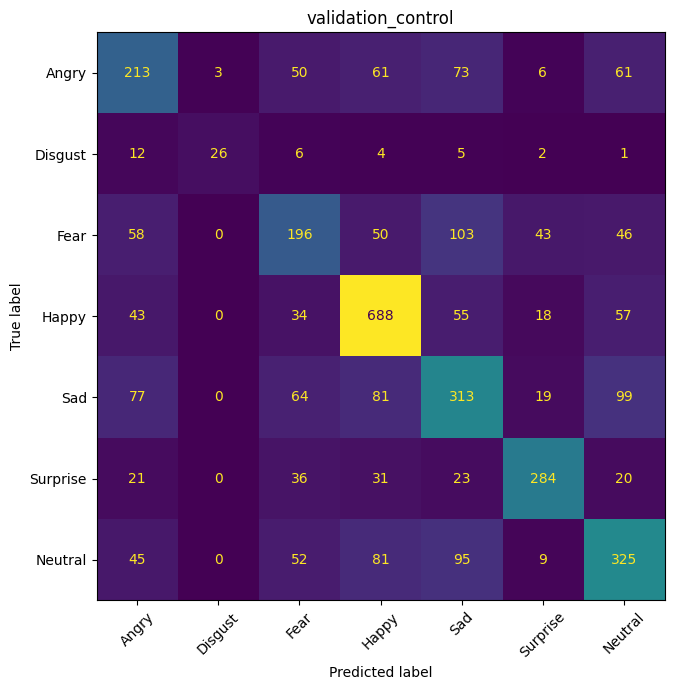

Baseline validation: {'accuracy': 0.5697966007244358, 'balanced_accuracy': 0.5404783581724973, 'macro_f1': 0.5623714552047204, 'predict_seconds': 55.255137500000274, 'evaluated_samples': 3589}


In [3]:
# Task 1 selected HOG + RBF SVM. Reuse its fitted pipeline directly.
baseline = joblib.load(ROOT / 'models/task1_best_baseline.pkl')
config = baseline['feature_config']
train_images, y_train = load_split('train')
validation_images, y_valid = load_split('validation')
X_train = features_for(train_images, config, 'train')
X_valid = features_for(validation_images, config, 'validation')
control = baseline['estimator']
control_scores, _ = evaluate(control, X_valid, y_valid, 'validation_control')
print('Baseline validation:', control_scores)


## 2. Predeclared tuning and class weighting ablation
Learned parameters (such as the support-vector decision function) are fitted from Training. Hyperparameters
(such as C) control that fitting and are selected using PublicTest macro F1.
An explicit ParameterGrid loop uses one fixed official validation set. Unlike pooling
Training/PublicTest in GridSearchCV, this lets each scaler/PCA see Training only.
Repeated validation comparisons can still overfit PublicTest; keep the search small.

C at one-third, unchanged, and three times the baseline value explores regularization on full Training.
Random seeds and all other settings stay fixed.

The 2x2 ablation is: control, tuning only, weighting only, tuning plus weighting. Tuning uses
class_weight=None. Then freeze its selected parameters before adding balancing, which
isolates weighting at two parameter settings. Weights n/(7*n_class) use Training counts only;
no evaluation examples are resampled. More minority recall may reduce majority accuracy.
No improvement is assumed in advance.

Execution setting: new SVC fits use a 1,024 MB kernel cache to limit repeated kernel computations. This changes computation rather than the fitting objective. The unchanged fitted baseline remains the control.

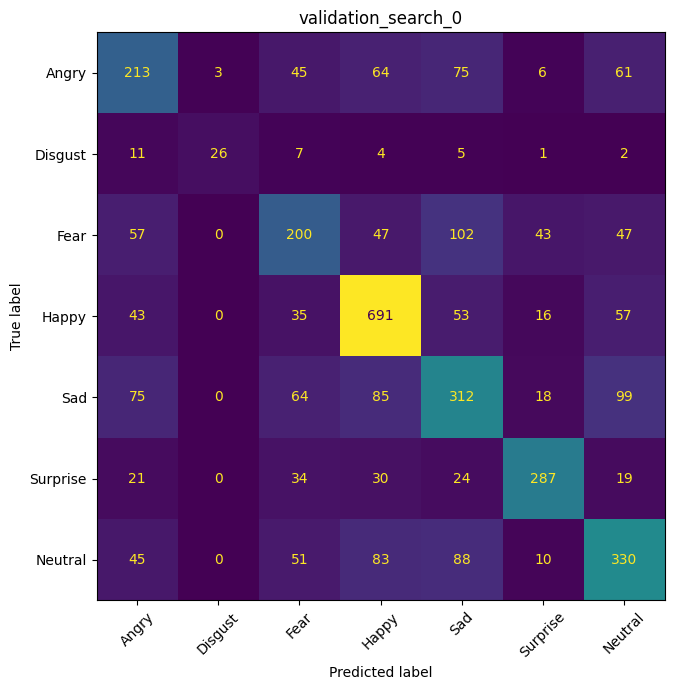

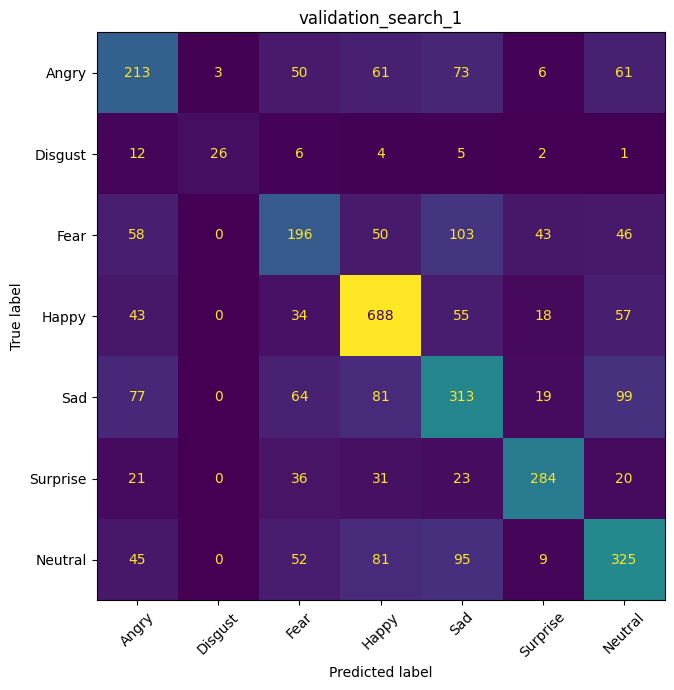

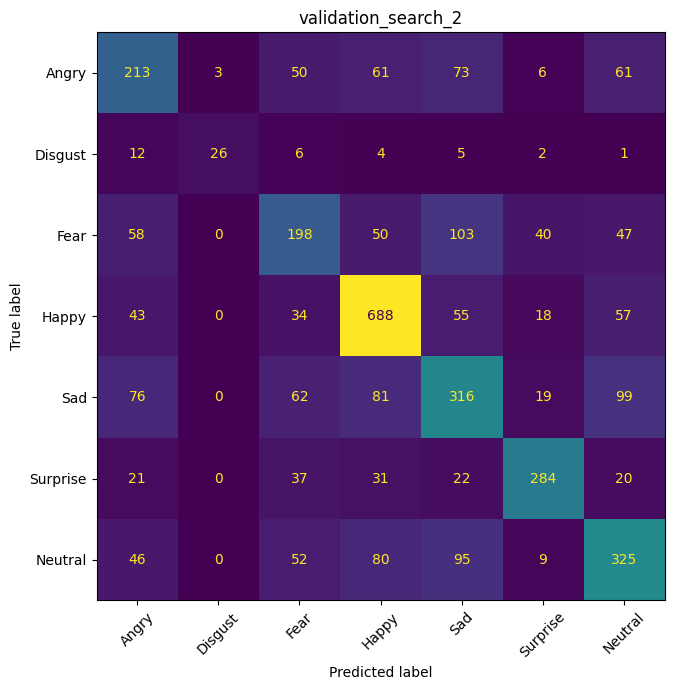

,candidate,parameters,fit_seconds,accuracy,balanced_accuracy,macro_f1,predict_seconds,evaluated_samples
0,0,"{""classifier__C"": 3.3333333333333335}",594.684759,0.573697,0.544100,0.566085,52.369117,3589
2,2,"{""classifier__C"": 30.0}",730.565365,0.571190,0.541711,0.563842,61.259028,3589
1,1,"{""classifier__C"": 10.0}",1484.573959,0.569797,0.540478,0.562371,54.240367,3589


In [4]:
from sklearn.model_selection import ParameterGrid
from sklearn.feature_selection import SelectPercentile, f_classif
classifier = control.named_steps['classifier']
# Explore stronger, unchanged and weaker regularization around the fixed baseline.
base_c = float(classifier.C)
grid = {'classifier__C': [base_c / 3, base_c, base_c * 3]}
search_rows, search_models = [], []
for i, parameters in enumerate(ParameterGrid(grid)):
    candidate = clone(control).set_params(**parameters,classifier__class_weight=None)
    # C=10 is the already fitted control, so reuse it rather than train it again.
    if repr(candidate)==repr(control):
        candidate=control
        fit_seconds=float(baseline['selection']['validation']['fit_seconds'])
    else:
        candidate,fit_seconds=fit_experiment(candidate,X_train,y_train,f'tuning_{i}')
    scores,_ = evaluate(candidate,X_valid,y_valid,f'validation_search_{i}')
    search_rows.append(dict(candidate=i,parameters=json.dumps(parameters),fit_seconds=fit_seconds,**scores))
    search_models.append(candidate)
search = pd.DataFrame(search_rows).sort_values(['macro_f1','balanced_accuracy','accuracy'],ascending=False)
search.to_csv(OUT / 'hyperparameter_search.csv',index=False); display(search)
# Choose C using validation macro F1 before testing class weighting.
tuned = search_models[int(search.iloc[0]['candidate'])]
experiments = {'control':control, 'tuning_only':tuned}
fit_times = {'control':baseline['selection']['validation']['fit_seconds'],
             'tuning_only':float(search.iloc[0]['fit_seconds'])}
# Balanced weighting increases the error penalty for less common Training classes.
for name,source in [('weighting_only',control),('tuning_and_weighting',tuned)]:
    candidate=clone(source).set_params(classifier__class_weight='balanced')
    candidate,fit_times[name]=fit_experiment(candidate,X_train,y_train,name)
    experiments[name]=candidate
# Additional controlled improvement: retain half the transformed features using
# training-only ANOVA scores. This can remove noisy dimensions but ignores interactions.
steps = [(name,clone(step)) for name,step in control.steps[:-1]]
steps += [('selection',SelectPercentile(f_classif,percentile=50)),
          ('classifier',clone(classifier))]
selected = Pipeline(steps)
selected,fit_times['feature_selection_only']=fit_experiment(selected,X_train,y_train,'feature_selection_only')
experiments['feature_selection_only']=selected


## 2b. Add facial geometry selected using KDEF Training
Use only the 56 KDEF Training identities and frontal photographs. Rank six
inter-eye-distance-normalized measurements with Training-only ANOVA scores:
mouth opening/width, left/right eye opening and left/right eyebrow-eye gap.
Keep the top three, then append those measurements to the FER HOG features.

Scale the HOG and geometry groups separately and fit the same SVM on FER Training.
KDEF test identities do not select the measurements; FER validation decides
whether adding them helps.


In [5]:

import pickle
from sklearn.compose import ColumnTransformer
from src.emotion_features import GEOMETRY_NAMES
from src.preprocess import preprocess_kdef_image
with (ROOT / 'auxFiles/kdef_subject_split.pkl').open('rb') as handle:
    subject_split=pickle.load(handle)
# Use only Training identities from the completed subject split.
train_subjects = set(subject_split['train_subjects'])
emotion_codes={'AN':0,'DI':1,'AF':2,'HA':3,'SA':4,'SU':5,'NE':6}
kdef_paths=[p for p in sorted((ROOT / 'data/KDEF_and_AKDEF/KDEF').rglob('*.JPG'))
            if p.stem[1:4] in train_subjects and p.stem[6:]=='S']
experiment_inputs = {name: (X_train, X_valid, config) for name in experiments}
prepared_by_path={}
manifest_path=ROOT/'results/teammate_integration/data_cache_manifest.json'
if manifest_path.is_file():
    record=json.loads(manifest_path.read_text());item=record.get('kdef_cache',{})
    cache_path=ROOT/item.get('path','__missing__')
    if cache_path.is_file():
        with cache_path.open('rb') as handle:prepared_cache=pickle.load(handle)
        for i,row in prepared_cache['meta'].iterrows():
            if row.subject in train_subjects:
                prepared_by_path[str(Path(row.path).resolve())]=prepared_cache['images'][i]
        print('Reusing KDEF Training crops:',len(prepared_by_path))
kdef_rows=[]; kdef_y=[]; kdef_failures=[]
predictor=load_predictor(LANDMARK_CONFIG)
for path in kdef_paths:
    try:
        # The lecturer preprocessor returns float32 [0,1], unlike the FER extractor.
        prepared=prepared_by_path.get(str(path.resolve()))
        if prepared is None:
            prepared=np.rint(preprocess_kdef_image(path)*255).clip(0,255).astype(np.uint8)
        kdef_rows.append(extract_model_features(prepared,dict(kind='geometry',landmarks=LANDMARK_CONFIG),predictor))
        kdef_y.append(emotion_codes[path.stem[4:6]])
    except (ValueError,RuntimeError) as exc:
        kdef_failures.append(dict(path=str(path.relative_to(ROOT)),reason=str(exc)))
pd.DataFrame(kdef_failures,columns=['path','reason']).to_csv(OUT / 'kdef_geometry_failures.csv',index=False)
# Rank only the KDEF Training measurements; never use its test subjects.
f_scores,_=f_classif(np.stack(kdef_rows),np.asarray(kdef_y))
indices=sorted(np.argsort(f_scores)[-3:].tolist())
pd.DataFrame(dict(feature=GEOMETRY_NAMES,f_score=f_scores,
    selected=[i in indices for i in range(6)])).to_csv(OUT / 'kdef_training_geometry_scores.csv',index=False)
print('KDEF candidates/retained/failures:',len(kdef_paths),len(kdef_rows),len(kdef_failures))
print('Selected KDEF-derived features:',[GEOMETRY_NAMES[i] for i in indices])
augmented_config=dict(kind='augmented',implementation=IMPLEMENTATION,base=baseline['feature_config'],
                      landmarks=LANDMARK_CONFIG,geometry_indices=indices)
# Reuse base features; only the new raw-landmark ratios need extraction.
geometry_config=dict(kind='geometry',implementation=IMPLEMENTATION,landmarks=LANDMARK_CONFIG)
train_ratios=features_for(train_images,geometry_config,'train')[:,indices]
valid_ratios=features_for(validation_images,geometry_config,'validation')[:,indices]
aug_train=np.column_stack([X_train,train_ratios])
aug_valid=np.column_stack([X_valid,valid_ratios])
if not np.isfinite(aug_train).all() or not np.isfinite(aug_valid).all():
    raise ValueError('Geometry failures changed coverage; investigate before a fair comparison.')
base_width=X_train.shape[1]
# Fit separate scalers so the three ratios do not change how HOG is scaled.
base_steps=[(n,clone(step)) for n,step in control.steps[:-1]]
base_transform=Pipeline(base_steps) if base_steps else 'passthrough'
ratio_transform=StandardScaler()
transform=ColumnTransformer([('original',base_transform,list(range(base_width))),
                             ('geometry',ratio_transform,list(range(base_width,base_width+len(indices))))])
geometry_model=Pipeline([('features',transform),('classifier',clone(classifier))])
geometry_model,fit_times['kdef_geometry_only']=fit_experiment(geometry_model,aug_train,y_train,'kdef_geometry_only')
experiments['kdef_geometry_only']=geometry_model
experiment_inputs['kdef_geometry_only']=(aug_train,aug_valid,augmented_config)
(OUT / 'kdef_experiment_status.json').write_text(json.dumps(dict(status='completed',retained=len(kdef_rows),failures=len(kdef_failures)),indent=2))


Reusing KDEF Training crops: 784


KDEF candidates/retained/failures: 784 784 0
Selected KDEF-derived features: ['mouth_opening', 'mouth_width', 'left_eye_opening']


63

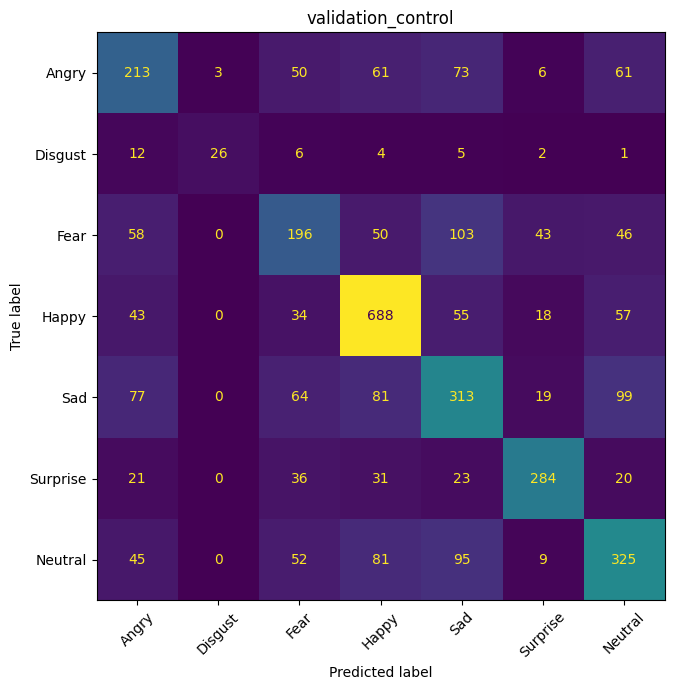

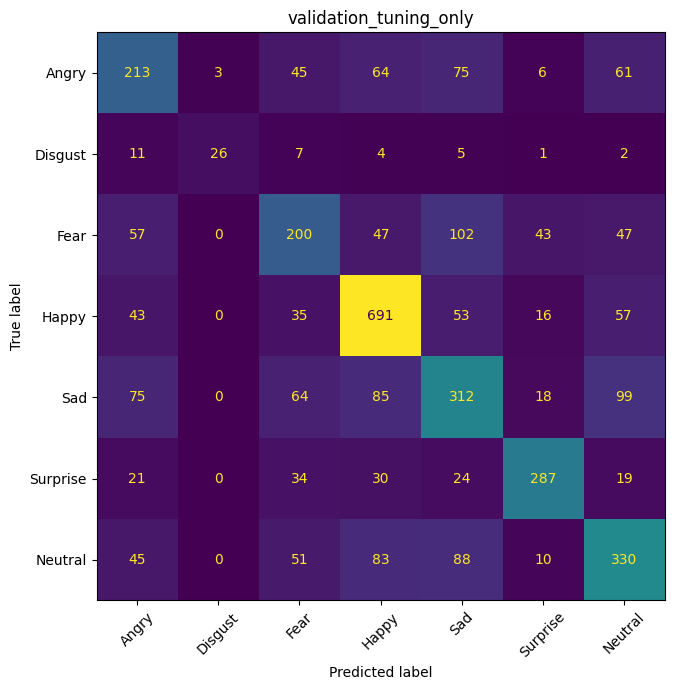

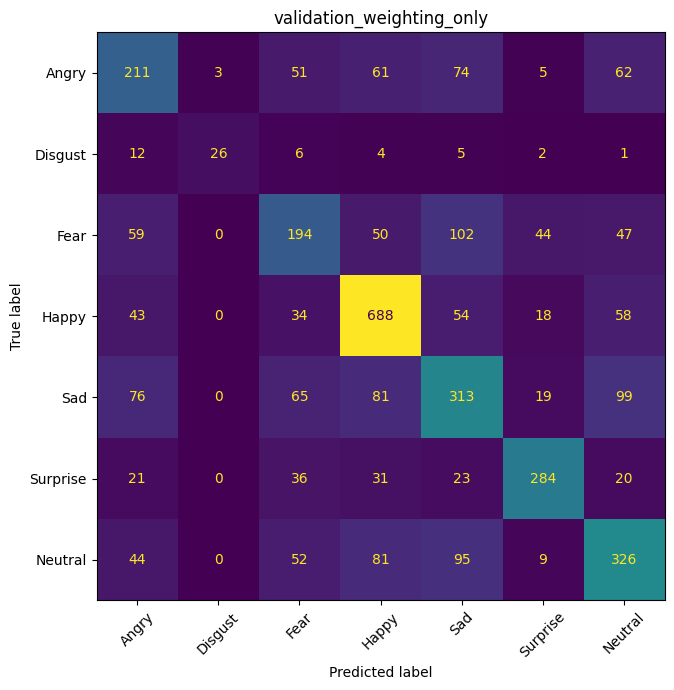

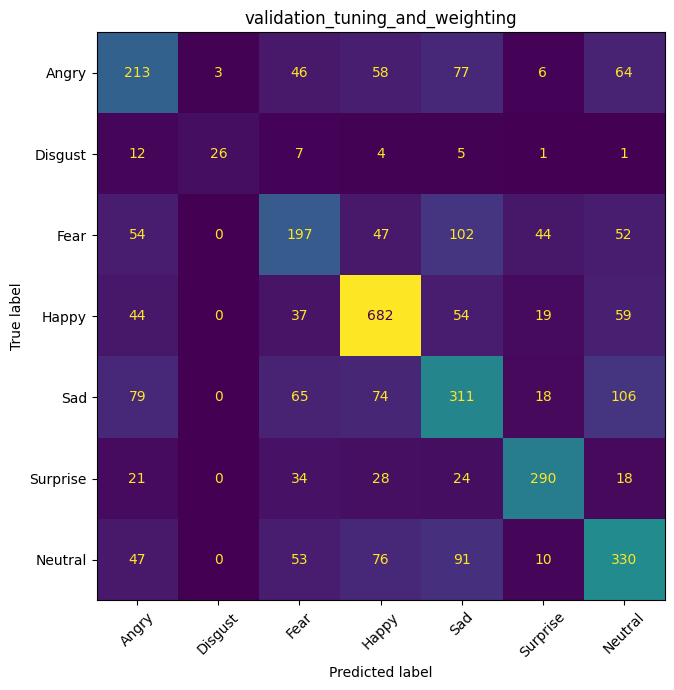

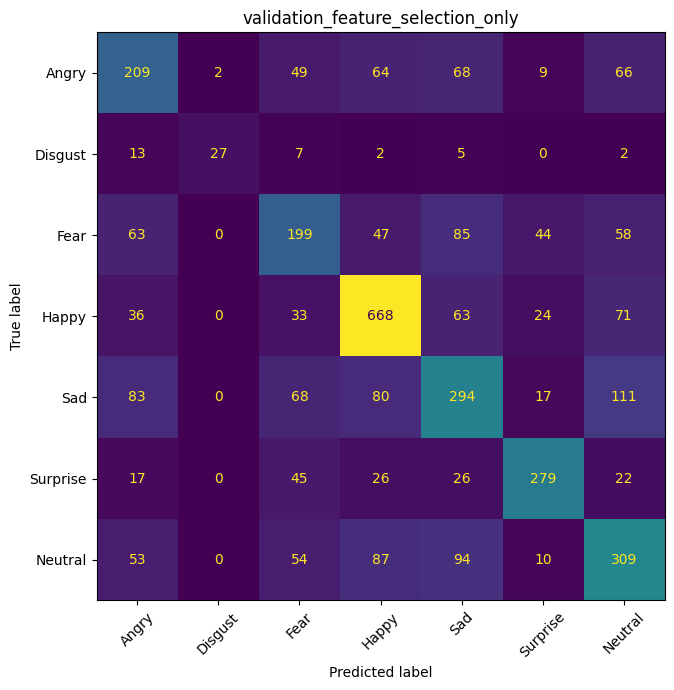

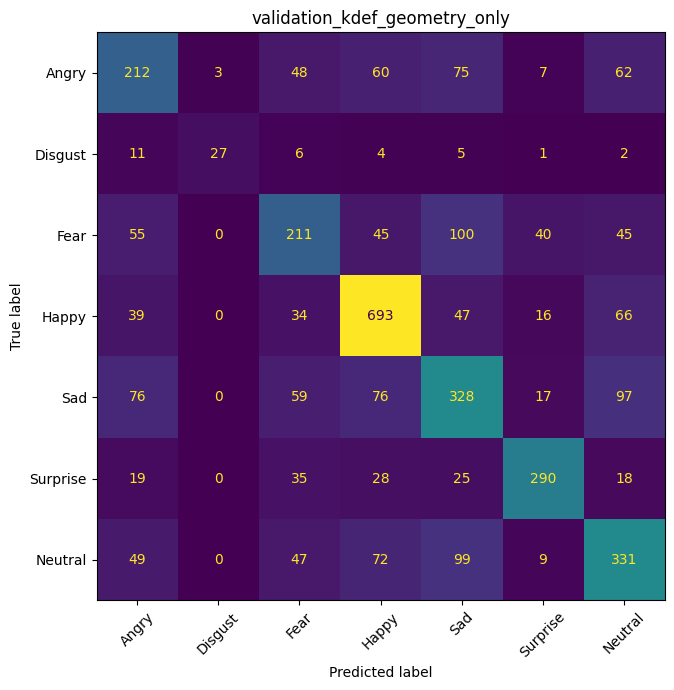

,experiment,fit_seconds,accuracy,balanced_accuracy,macro_f1,predict_seconds,evaluated_samples,delta_macro_f1
5,kdef_geometry_only,759.123329,0.582892,0.554601,0.576684,95.147593,3589,0.014313
1,tuning_only,594.684759,0.573697,0.544100,0.566085,69.628806,3589,0.003714
3,tuning_and_weighting,747.163156,0.570911,0.542613,0.563955,60.655265,3589,0.001583
0,control,1484.573959,0.569797,0.540478,0.562371,62.637595,3589,0.000000
2,weighting_only,821.020589,0.568961,0.539526,0.561391,63.427719,3589,-0.000980
4,feature_selection_only,475.932642,0.553079,0.529834,0.552084,29.743056,3589,-0.010288


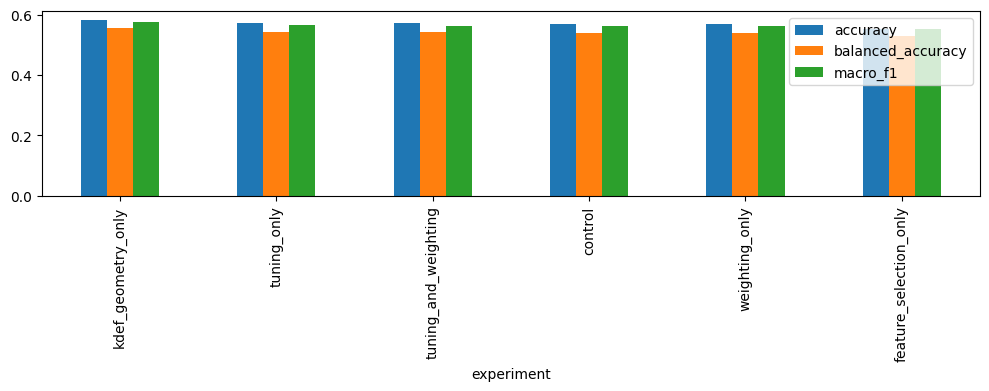

In [6]:
# Compare every experiment on the same validation images and labels.
rows=[]
for name,estimator in experiments.items():
    scores,prediction=evaluate(estimator,experiment_inputs[name][1],y_valid,f'validation_{name}')
    rows.append(dict(experiment=name,fit_seconds=fit_times[name],**scores))
comparison=pd.DataFrame(rows).sort_values(['macro_f1','balanced_accuracy','accuracy'],ascending=False,kind='stable')
comparison['delta_macro_f1']=comparison.macro_f1-control_scores['macro_f1']
comparison.to_csv(OUT / 'validation_improvements.csv',index=False); display(comparison)
comparison.set_index('experiment')[['accuracy','balanced_accuracy','macro_f1']].plot.bar(figsize=(10,4))
plt.tight_layout(); plt.savefig(OUT / 'validation_improvements.png'); plt.show()

## 3. Select, export and freeze before final evaluation
The control remains eligible: a technique can hurt performance. If the control wins, none of the attempted improvements exceeded it. Per-class
precision and recall describe metric trade-offs; aggregate scores alone do not establish causality.
Feature selection is already a predeclared alternative if tuning/weighting do not help.
The additional KDEF experiment uses only the corrected Training identities and frontal images.
The same Training-only fitting is retained for a fair final test comparison.

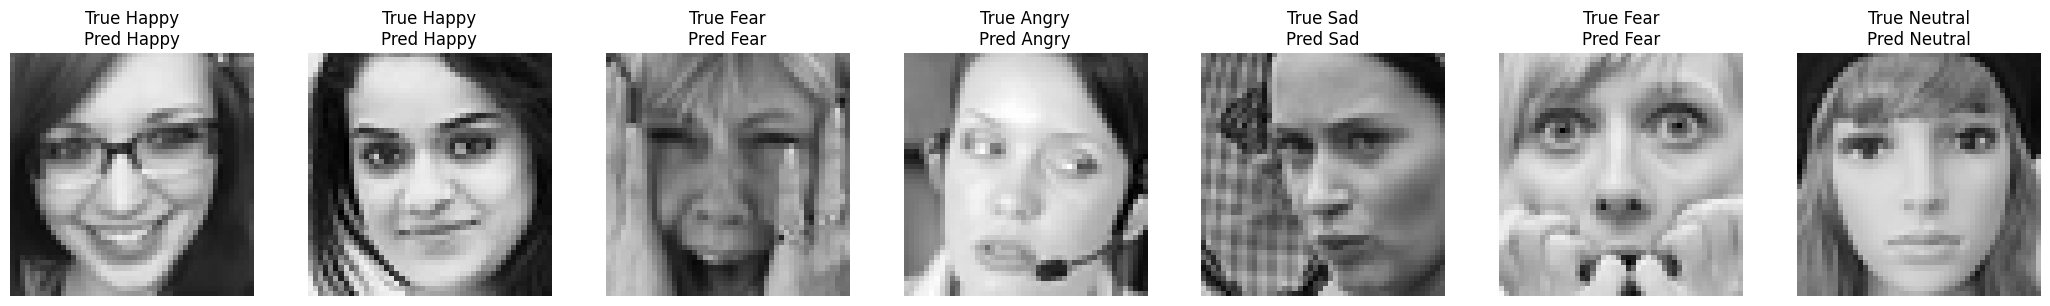

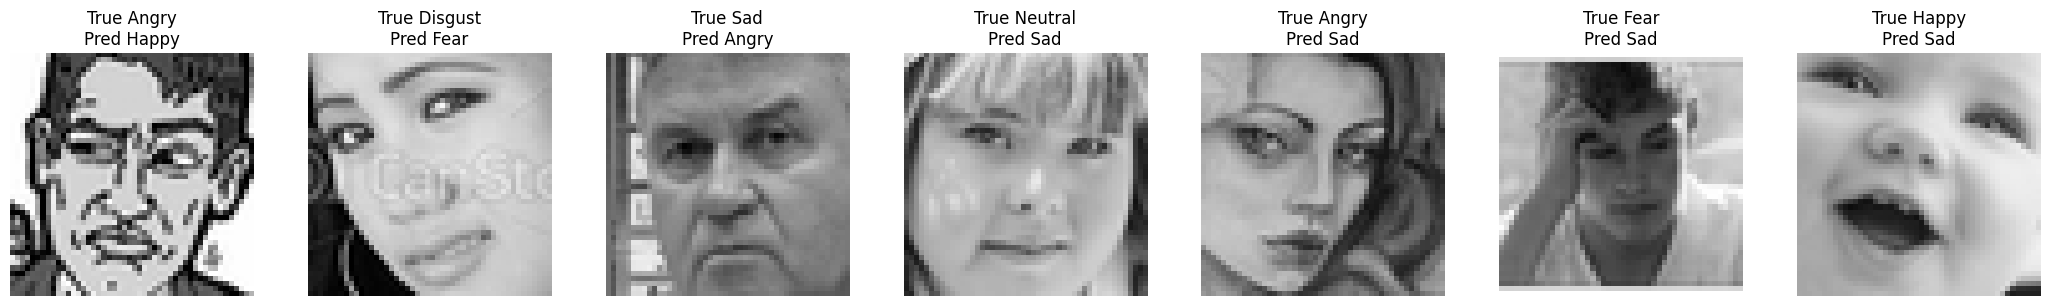

In [7]:
# Freeze the validation winner before loading any final test images.
best_row=comparison.iloc[0]; winner_name=best_row['experiment']; winner=experiments[winner_name]
selection=dict(experiment=winner_name,validation=best_row.to_dict(),
               baseline_selection=baseline['selection'])
winner_config=experiment_inputs[winner_name][2]
artifact=save_artifact(winner,winner_config,ROOT / 'models/task5_teammate_best_model.pkl',
    selection,baseline['data_protocol'])
(OUT / 'selected_parameters.txt').write_text(str(winner.get_params()))
show_errors(validation_images,y_valid,winner.predict(experiment_inputs[winner_name][1]),'selected_validation')

## 4. Final test evaluation
Evaluate the frozen winner on all 3,589 PrivateTest images and compare with the
saved Task 1 result. Do not revise candidates or the winner using these scores.


test (3589, 48, 48) class counts: [491  55 528 879 594 416 626]


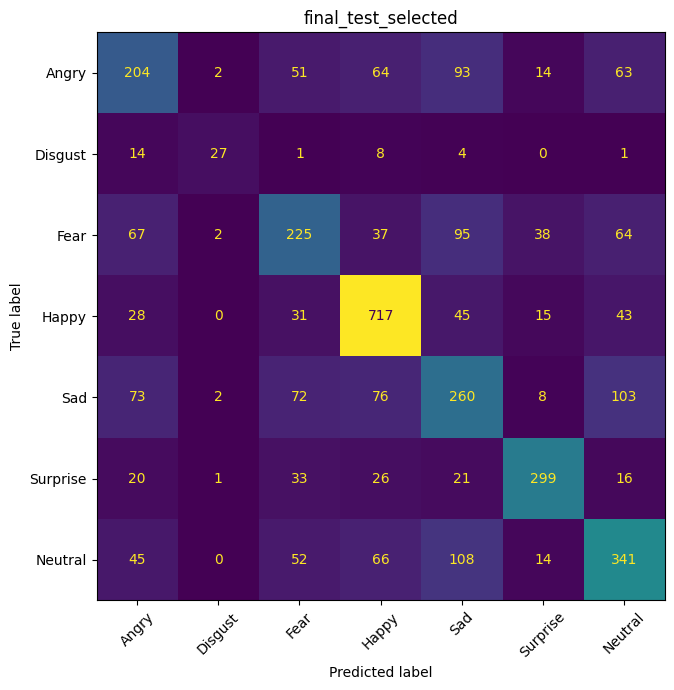

{'accuracy': 0.5775982167734746, 'balanced_accuracy': 0.5499160857907198, 'macro_f1': 0.5673176732579882, 'predict_seconds': 91.80316230000062, 'evaluated_samples': 3589, 'retained': 3589, 'total': 3589, 'selected_experiment': 'kdef_geometry_only', 'delta_test_macro_f1': -0.0009613013950970917}


In [8]:
# Load the test partition only after model selection and export.
test_images, test_labels = load_split('test')
test_features = features_for(test_images, config, 'test')
if winner_config['kind'] == 'augmented':
    ratio_config = dict(kind='geometry', implementation=IMPLEMENTATION, landmarks=LANDMARK_CONFIG)
    ratios = features_for(test_images, ratio_config, 'test')[:, winner_config['geometry_indices']]
    test_features = np.column_stack([test_features, ratios])

scores, _ = evaluate(winner, test_features, test_labels, 'final_test_selected')
base_test = json.loads((ROOT / 'results/teammate_task1/final_test.json').read_text())
scores.update(retained=len(test_labels), total=len(test_labels), selected_experiment=winner_name,
              delta_test_macro_f1=scores['macro_f1'] - base_test['macro_f1'])
(OUT / 'final_test.json').write_text(json.dumps(scores, indent=2))
print(scores)


## 5. Measured observations

Validation selected **kdef_geometry_only**. On 3,589 PrivateTest images, accuracy is **0.5776**, balanced accuracy **0.5499**, and macro F1 **0.5673**, a difference of **-0.0010** from the Task 1 control. The table reports observed changes on the same test population; it is not a significance test.

Validation macro-F1 changes relative to control: tuning_only: +0.0037; weighting_only: -0.0010; tuning_and_weighting: +0.0016; feature_selection_only: -0.0103; kdef_geometry_only: +0.0143.

Weighting alone changed validation accuracy by -0.0008, balanced accuracy by -0.0010, and macro F1 by -0.0010. Class weighting changes the fitting penalties; precision and recall trade-offs determine whether F1 improves. The highest per-class recall change is Neutral (+0.0016); precision and support provide additional context. KDEF Training selected these three ratios: mouth_opening, mouth_width, left_eye_opening. Their ranking uses Training identities only; the FER validation comparison determines usefulness here, rather than establishing transfer accuracy.

| emotion | baseline_F1 | final_F1 | delta_F1 |
| --- | --- | --- | --- |
| Angry | 0.4369 | 0.4331 | -0.0038 |
| Disgust | 0.6222 | 0.6067 | -0.0155 |
| Fear | 0.4580 | 0.4532 | -0.0048 |
| Happy | 0.7543 | 0.7656 | 0.0114 |
| Sad | 0.4331 | 0.4262 | -0.0069 |
| Surprise | 0.7277 | 0.7438 | 0.0160 |
| Neutral | 0.5457 | 0.5426 | -0.0032 |

The largest numerical class change is Surprise (+0.0160); the smallest is Disgust (-0.0155). Precision, recall and support provide context for these differences. The validation ablations compare the predeclared modifications; the selected model was not revised after this test result.

The selected candidate changed validation macro F1 by +0.0143, but changed final test macro F1 by -0.0010. Test accuracy changed by +0.0022. The validation gain therefore did not translate into a test macro-F1 improvement. This run does not establish a consistent generalization benefit. The validation choice remains frozen; switching models using these test scores would make the test set part of selection.